## Лабораторная работа №1 | Вариант 6

Выполнил: Кудрявцев Егор Алексеевич, М8О-311БВ-24

### 1. Numpy

In [3]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

Выполнил: 

In [38]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [39]:
np.diag(np.arange(1, 5), k=-1)

array([[0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 2, 0, 0, 0],
       [0, 0, 3, 0, 0],
       [0, 0, 0, 4, 0]])

3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

In [ ]:
9
10

4. Как найти самое часто встречаемое значение между двумя массивами? 

In [6]:
a = np.array([1, 2, 2, 3, 4, 2])
b = np.array([2, 3, 3, 5, 2, 1])
values, counts = np.unique(np.concatenate([a, b]), return_counts=True)
values[counts.argmax()]

np.int64(2)

5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

In [41]:
np.seterr(all="ignore")

{'divide': 'ignore', 'over': 'ignore', 'under': 'ignore', 'invalid': 'ignore'}

6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [8]:
def generate_ints():
    for i in range(10):
        yield i

np.fromiter(generate_ints(), dtype=int)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [14]:
arr = np.random.random(10)
arr.sort()
arr

array([0.06965497, 0.0726228 , 0.07926546, 0.34350223, 0.40889965,
       0.41817263, 0.54524633, 0.77135829, 0.85315642, 0.90271874])

8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [15]:
cartesian = np.random.random((10, 2))
x, y = cartesian[:, 0], cartesian[:, 1]
r = np.sqrt(x ** 2 + y ** 2)
theta = np.arctan2(y, x)
r, theta

(array([0.75779908, 0.81050959, 0.25870683, 1.09821336, 0.9494674 ,
        0.8482442 , 1.12010334, 0.82988442, 0.82698964, 0.96229756]),
 array([0.09788014, 0.36450595, 0.31893871, 1.11025447, 1.5488265 ,
        1.19519581, 0.58394934, 0.37854623, 0.36557184, 0.68590544]))

9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [16]:
pixel = np.dtype([
    ("x", np.int32),
    ("y", np.int32),
    ("r", np.uint8),
    ("g", np.uint8),
    ("b", np.uint8),
])
np.zeros(1, dtype=pixel)

array([(0, 0, 0, 0, 0)],
      dtype=[('x', '<i4'), ('y', '<i4'), ('r', 'u1'), ('g', 'u1'), ('b', 'u1')])

10. Как конвертировать тип массив от float32 в int32 in place?

In [17]:
arr = (np.random.rand(10) * 100).astype(np.float32)
arr_int = arr.view(np.int32)
arr_int[:] = arr
arr_int

array([63, 64, 23, 15, 31, 51, 90, 67, 52, 42], dtype=int32)

### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [18]:
import pandas as pd

In [19]:
# Load dataset here
df = pd.read_csv("student_perfomance.csv")

1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [20]:
df["Sleep_Hours"].mean()

np.float64(7.029060087785682)

2. Сколько процентов студентов посещают внеклассовые активности?

In [21]:
(df["Extracurricular_Activities"] == "Yes").mean() * 100

np.float64(59.60345088542455)

3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

In [22]:
gender_means = df.groupby("Gender")["Exam_Score"].mean()
gender_means, gender_means["Female"] > gender_means["Male"]

(Gender
 Female    67.244898
 Male      67.228894
 Name: Exam_Score, dtype: float64,
 np.True_)

4. Выведите 25 и 75 перцентили времени сна студентов

In [23]:
df["Sleep_Hours"].quantile([0.25, 0.75])

0.25    6.0
0.75    8.0
Name: Sleep_Hours, dtype: float64

5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [45]:
q25, q75 = df["Sleep_Hours"].quantile([0.25, 0.75])
more_sleep = df.loc[df["Sleep_Hours"] >= q75, "Exam_Score"].mean()
less_sleep = df.loc[df["Sleep_Hours"] <= q25, "Exam_Score"].mean()

print("Правда" if more_sleep > less_sleep else "Ложь")

Ложь


6. Влияет ли физическая активность на результаты экзамена?

In [ ]:
df.groupby("Physical_Activity")["Exam_Score"].mean()

# По результату слабая связь

Physical_Activity
0    67.521739
1    66.969121
2    67.185003
3    67.196071
4    67.313016
5    67.603878
6    68.093750
Name: Exam_Score, dtype: float64

7. Правда ли, что слуденты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

In [46]:
higher = df["Parental_Education_Level"].isin(["College", "Postgraduate"])
higher_mean = df.loc[higher, "Exam_Score"].mean()
other_mean = df.loc[~higher, "Exam_Score"].mean()

print("Правда" if higher_mean > other_mean else "Ложь")

Правда


8. Как влияет участие родителей на результаты экзаменов

In [ ]:
df.groupby("Parental_Involvement")["Exam_Score"].mean().reindex(["Low", "Medium", "High"])

# По результату чем выше участие родителей, тем выше балл

Parental_Involvement
Low       66.358265
Medium    67.098156
High      68.092767
Name: Exam_Score, dtype: float64

9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [47]:
high_income = df.loc[df["Family_Income"] == "High", "Exam_Score"].mean()
other_income = df.loc[df["Family_Income"] != "High", "Exam_Score"].mean()
print("Правда" if high_income > other_income else "Ложь")

Правда


10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [52]:
mask = (df["Family_Income"] == "Low") & (df["Internet_Access"] == "No")
print((df.loc[mask, "Exam_Score"] > 70).mean() * 100, "%")

8.056872037914692 %


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

count    6607.000000
mean        7.029060
std         1.468120
min         4.000000
max        10.000000
skew       -0.023805
Name: Sleep_Hours, dtype: float64
Sleep_Hours
4      309
5      695
6     1376
7     1741
8     1399
9      775
10     312
Name: count, dtype: int64


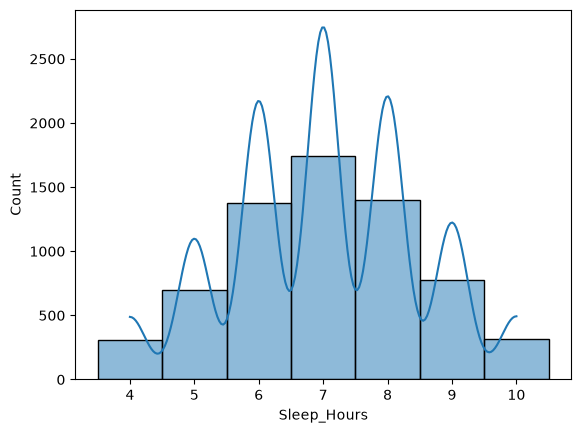

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df["Sleep_Hours"], kde=True, discrete=True)

print(df["Sleep_Hours"].agg(["count", "mean", "std", "min", "max", "skew"]))
print(df["Sleep_Hours"].value_counts().sort_index())

plt.show()

# Гистограмма сна симметричная и одновершинная, пик на 7 часах, хвосты на 4 и 10. По форме это примерно нормальное распределение

2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

        count       mean  median       std
Gender                                    
Female   2793  20.005013    20.0  5.997251
Male     3814  19.953592    20.0  5.986408


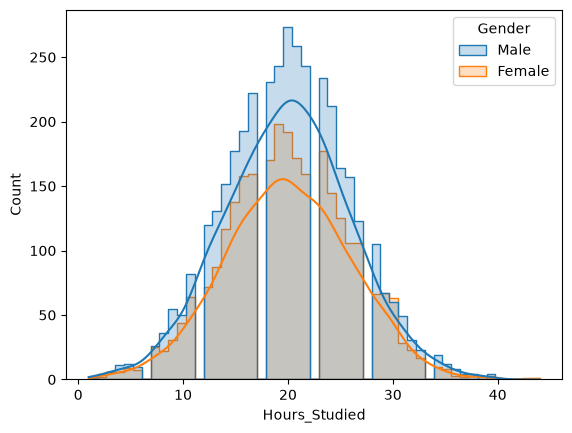

In [59]:
sns.histplot(data=df, x="Hours_Studied", hue="Gender", element="step", kde=True)

print(df.groupby("Gender")["Hours_Studied"].agg(["count", "mean", "median", "std"]))

plt.show()

# У мальчиков и девочек одна и та же форма: колокол с вершиной около 20 часов в неделю. Синяя гистограмма выше, потому что мужчин в выборке больше. Средние почти совпадают: 19.95 и 20.01

3. Как зависит результат конечного экзамена от результата первого экзамена

Corr: 0.175079087022911


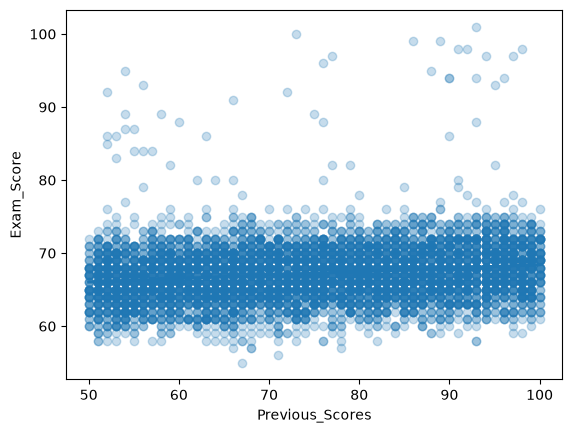

In [66]:
sns.regplot(data=df, x="Previous_Scores", y="Exam_Score", scatter_kws={"alpha": 0.25})

print("Corr:", df["Previous_Scores"].corr(df["Exam_Score"]))

plt.show()

# Зависимость итогового балла от первого экзамена слабая и положительная, корреляция 0.18

4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

       count      mean  median       std  min  max
group                                             
< 85    6572  7.029519     7.0  1.467358    4   10
>= 85     35  6.942857     7.0  1.625945    4   10


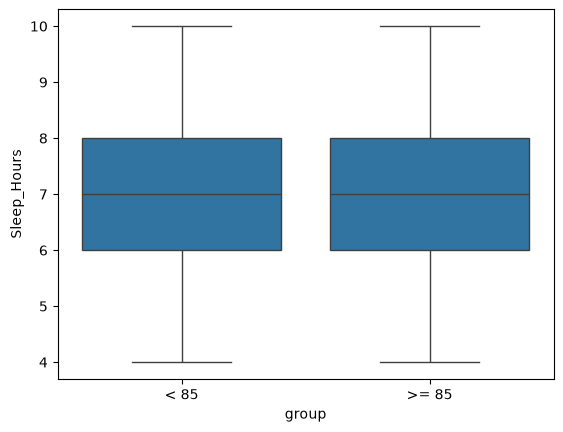

In [62]:
plot_df = df.assign(group=np.where(df["Exam_Score"] >= 85, ">= 85", "< 85"))
sns.boxplot(data=plot_df, x="group", y="Sleep_Hours")

print(plot_df.groupby("group")["Sleep_Hours"].agg(["count", "mean", "median", "std", "min", "max"]))

plt.show()

# Ящики сна для оценок ниже 85 и от 85 почти совпадают: медиана 7, ящик от 6 до 8, усы от 4 до 10. Сон у сильных и у остальных одинаковый. Группа 85 и выше маленькая — 35 человек.

5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

Corr: 0.15652518539225346
                   count       mean
Tutoring_Sessions                  
0                   1513  66.489755
1                   2179  66.980266
2                   1649  67.567010
3                    836  67.894737
4                    301  68.229236
5                    103  69.067961
6                     18  71.666667
7                      7  69.857143
8                      1  69.000000


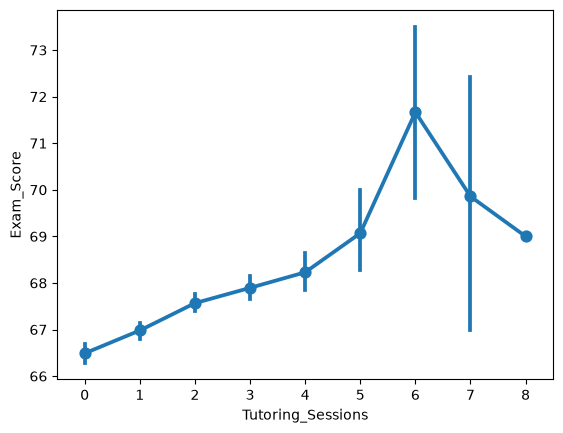

In [ ]:
sns.pointplot(data=df, x="Tutoring_Sessions", y="Exam_Score")

print("Corr:", df["Tutoring_Sessions"].corr(df["Exam_Score"]))
print(df.groupby("Tutoring_Sessions")["Exam_Score"].agg(["count", "mean"]))

plt.show()

# С 0 до 6 занятий средний балл ровно растёт: с 66.5 до 71.7. После 6 линия падает, но интервалы огромные: на 7 занятиях 7 человек, на 8 один. Есть монотонный рост примерно до 6 занятий в месяц. Корреляция 0.16.

6. Как физическая активность влияет на успеваемость?

Corr: 0.02782443618025734
                   count       mean
Physical_Activity                  
0                     46  67.521739
1                    421  66.969121
2                   1627  67.185003
3                   2545  67.196071
4                   1575  67.313016
5                    361  67.603878
6                     32  68.093750


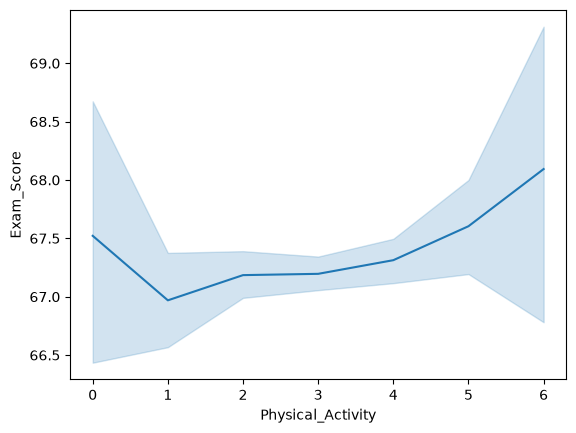

In [ ]:
sns.lineplot(data=df, x="Physical_Activity", y="Exam_Score")

print("Corr:", df["Physical_Activity"].corr(df["Exam_Score"]))
print(df.groupby("Physical_Activity")["Exam_Score"].agg(["count", "mean"]))

plt.show()

# Физическая активность успеваемость заметно не меняет

7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

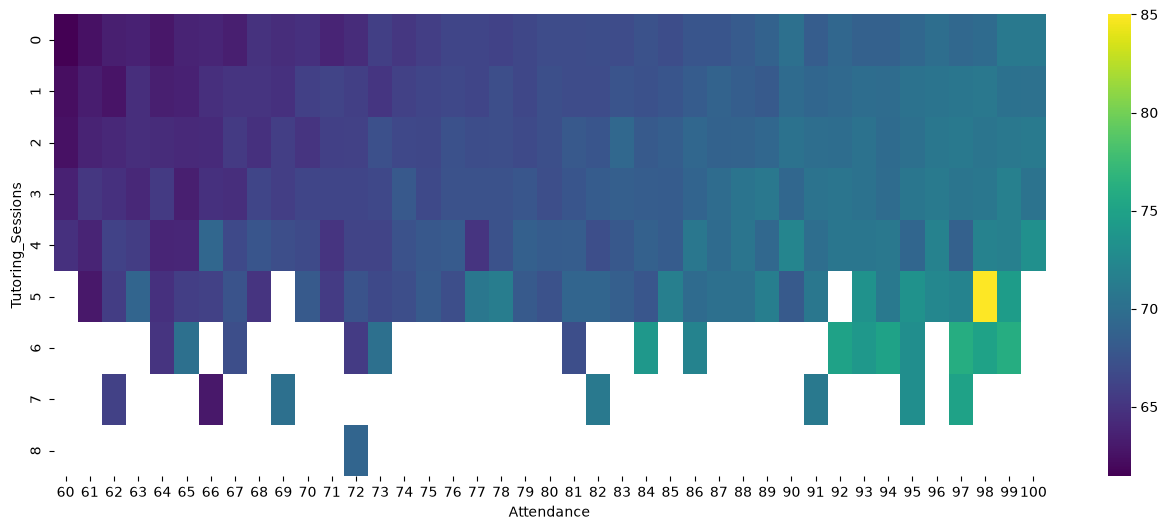

In [70]:
pivot = df.pivot_table(
    index="Tutoring_Sessions",
    columns="Attendance",
    values="Exam_Score",
    aggfunc="mean",
)

plt.figure(figsize=(16, 6))
sns.heatmap(pivot, cmap="viridis")
plt.show()